# WP1: Wind Farm B — Exploratory Data Analysis, Time-Series Properties & Preprocessing

**Dataset:** CARE to Compare — Wind Farm B (Offshore Wind Turbines, 10-minute SCADA resolution, 257 columns)  
**Reference:** Gück et al. (2024), *CARE to Compare: A Real-World Benchmark Dataset for Early Fault Detection in Wind Turbine Data*, arXiv:2404.10320v2.

---
## Step 1: Imports & Loading the Metadata (`event_info.csv` & `feature_description.csv`)

### Why do we start here?
Before loading 90 MB sensor files, we need to understand:
1. **How many datasets exist in Wind Farm B?** (15 datasets total: **6 anomaly events** and **9 normal control datasets**).
2. **What kind of faults happen?**Looking at `event_description`, Wind Farm B has two main failure modes:
   - **High temperature in transformer cell** (Events `34`, `7`, `19`)
   - **Rotor / Main Bearing Damage** (Events `53`, `27`, `77`)
3. **What do the 63 sensors measure?** `feature_description.csv` tells us which sensors are **angles** (`is_angle == True`), which are **cumulative counters** (`is_counter == True`), and what physical units they have (`°C`, `m/s`, `kW`, `rpm`, `mG`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

# Path to your Wind Farm B folder
DATA_DIR = Path(r"D:\Bootcamp\Projects\wind-turbine-anomaly-detection\data\raw\Wind Farm B")
DATASETS_DIR = DATA_DIR / "datasets"

# 1. Load event_info.csv (note: CARE to Compare uses semicolon ';' delimiter)
event_info = pd.read_csv(DATA_DIR / "event_info.csv", sep=";")
event_info["event_start"] = pd.to_datetime(event_info["event_start"])
event_info["event_end"] = pd.to_datetime(event_info["event_end"])
event_info["duration_days"] = (event_info["event_end"] - event_info["event_start"]).dt.total_seconds() / (3600 * 24)

print(f"Total datasets in Wind Farm B: {len(event_info)}")
print(event_info["event_label"].value_counts())
display(event_info.sort_values(["event_label", "asset_id"]))

Total datasets in Wind Farm B: 15
event_label
normal     9
anomaly    6
Name: count, dtype: int64


,asset_id,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description,duration_days
2,6,53,anomaly,2023-12-26 16:40:00,52559,2024-02-06 16:30:00,58606,Rotor Bearing 2 - Damage,41.993056
3,7,27,anomaly,2023-09-01 00:00:00,52619,2023-11-01 00:00:00,61403,Turbine is stopped due to a main bearing damage,61.000000
4,11,19,anomaly,2023-02-03 00:00:00,52673,2023-02-23 00:00:00,55553,high temperature in transformer cell,20.000000
5,12,77,anomaly,2023-06-01 00:00:00,52991,2023-07-31 00:00:00,61631,Turbine is in standstill since 01.08 due to ro...,60.000000
1,13,7,anomaly,2023-07-01 00:00:00,52703,2023-08-01 00:00:00,57167,high temperature in transformer cell,31.000000
0,14,34,anomaly,2023-08-24 00:00:00,52531,2023-09-15 00:00:00,55699,high temperature in transformer cell,22.000000
8,0,21,normal,2023-09-22 20:10:00,52217,2023-10-01 20:10:00,53513,NaN,9.000000
6,2,83,normal,2023-07-01 00:00:00,52329,2023-09-30 00:00:00,65433,NaN,91.000000
14,5,82,normal,2023-09-26 23:00:00,52975,2023-10-08 23:00:00,54703,NaN,12.000000
10,6,23,normal,2023-09-17 17:30:00,52559,2023-09-27 11:50:00,53965,NaN,9.763889


In [2]:
# 2. Load feature_description.csv
feature_desc = pd.read_csv(DATA_DIR / "feature_description.csv", sep=";")
print(f"Total base sensors: {len(feature_desc)} (each has avg, max, min, std -> 63 x 4 = 252 sensor columns + 5 metadata columns = 257 columns)")

# Check special sensor types: Angles and Cumulative Counters
print("\n--- Angular Sensors (need sin/cos cyclic encoding) ---")
display(feature_desc[feature_desc["is_angle"] == True])

print("\n--- Counter Sensors (cumulative kWh / kvarh - non-stationary!) ---")
display(feature_desc[feature_desc["is_counter"] == True])

print("\n--- Temperature Sensors (°C) ---")
temp_sensors = feature_desc[feature_desc["description"].str.contains("temp", case=False, na=False)]
display(temp_sensors)

Total base sensors: 63 (each has avg, max, min, std -> 63 x 4 = 252 sensor columns + 5 metadata columns = 257 columns)

--- Angular Sensors (need sin/cos cyclic encoding) ---


,sensor_name,statistics_type,description,unit,is_angle,is_counter
4,sensor_4,"average,maximum,minimum,std_dev",Absolute wind direction,�,True,False
10,sensor_10,"maximum,std_dev,average,minimum",Pitch angle,�,True,False
21,sensor_21,"minimum,maximum,std_dev,average",Nacelle direction,�,True,False



--- Counter Sensors (cumulative kWh / kvarh - non-stationary!) ---


,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,"maximum,minimum,average,std_dev",Total negative reactive power,kvarh,False,True
1,sensor_1,"maximum,std_dev,average,minimum",Total negative active power,kWh,False,True
2,sensor_2,"average,minimum,maximum,std_dev",Total positive reactive power,kvarh,False,True
3,sensor_3,"maximum,std_dev,minimum,average",Total positive active power,kWh,False,True



--- Temperature Sensors (°C) ---


,sensor_name,statistics_type,description,unit,is_angle,is_counter
8,sensor_8,"maximum,average,minimum,std_dev",Outside temperature,�C,False,False
22,sensor_22,"std_dev,maximum,minimum,average",Hub temperature,�C,False,False
31,sensor_31,"average,minimum,std_dev,maximum",Temperature internal consumption transformer,�C,False,False
32,sensor_32,"average,maximum,minimum,std_dev",Generator bearing temperature 1,�C,False,False
33,sensor_33,"average,maximum,minimum,std_dev",Generator bearing temperature 2,�C,False,False
34,sensor_34,"average,maximum,std_dev,minimum",Gearbox bearing temperature 1,�C,False,False
35,sensor_35,"minimum,std_dev,average,maximum",Gearbox bearing temperature 2,�C,False,False
36,sensor_36,"minimum,std_dev,maximum,average",Gearbox bearing temperature 3,�C,False,False
37,sensor_37,"minimum,maximum,std_dev,average",Gearbox bearing temperature 4,�C,False,False
38,sensor_38,"maximum,minimum,std_dev,average",Gearbox oil inlet temperature,�C,False,False


---
## Step 2: Inspecting a Single Turbine Time-Series & Checking Data Quality

Let's load **Event `34`** (Asset 14 — *high temperature in transformer cell*) and **Event `53`** (Asset 6 — *Rotor Bearing 2 - Damage*) to inspect:
1. **Time span & `train_test` split:** ~1 year of `train` data followed by `prediction` data.
2. **Timestamp continuity:** Is the 10-minute grid continuous, or are there missing timestamps / `NaN` gaps?
3. **Operational states (`status_type_id`):**
   - `0` = Normal Operation
   - `1` = Derated (reduced power)
   - `2` = Idling (no power generation)
   - `3` = Scheduled Service / Maintenance
   - `4` = Downtime / Fault
   - `5` = Other

In [3]:
def load_turbine_csv(event_id: int) -> pd.DataFrame:
    df = pd.read_csv(DATASETS_DIR / f"{event_id}.csv", sep=";")
    df["time_stamp"] = pd.to_datetime(df["time_stamp"])
    df = df.sort_values("time_stamp").reset_index(drop=True)
    return df

df_34 = load_turbine_csv(34)
print(f"Dataset 34 shape: {df_34.shape}")
print(f"Time range: {df_34['time_stamp'].min()}  -->  {df_34['time_stamp'].max()}")
print("\nTrain vs Prediction split counts:")
print(df_34["train_test"].value_counts())

print("\nOperational Status (status_type_id) distribution:")
print(df_34.groupby(["train_test", "status_type_id"]).size().unstack(fill_value=0))

# Check timestamp regularity (should be 10 minutes)
time_diffs = df_34["time_stamp"].diff()
print("\nTimestamp step differences:")
print(time_diffs.value_counts().head(5))

# Check missing values
nan_counts = df_34.isna().sum()
print(f"\nColumns with NaNs: {(nan_counts > 0).sum()} out of {df_34.shape[1]}")

Dataset 34 shape: (56564, 257)
Time range: 2022-08-24 00:00:00  -->  2023-09-21 00:00:00

Train vs Prediction split counts:
train_test
train         52531
prediction     4033
Name: count, dtype: int64

Operational Status (status_type_id) distribution:
status_type_id      0     1    4     5
train_test                            
prediction       3889    61   18    65
train           43971  6608  302  1650

Timestamp step differences:
time_stamp
0 days 00:10:00    56558
0 days 00:20:00        2
0 days 00:30:00        1
0 days 02:00:00        1
0 days 02:30:00        1
Name: count, dtype: int64

Columns with NaNs: 1 out of 257


---
## Step 3: Key Time-Series Visualizations for WP1 Documentation

In your documentation/resume, you want **3 high-impact scientific visualizations**:
1. **Power Curve (`wind_speed_61_avg` vs. `power_62_avg`) colored by `status_type_id`:** Proves why filtering `status_type_id == 0` is essential during training (maintenance/idling points lie at 0 kW even at high wind speeds).
2. **Seasonality & Ambient Temperature Dependency:** Shows how internal temperatures (`sensor_47_avg` = Transformer cell temp, `sensor_52_avg` = Rotor bearing temp 2) follow outside temperature (`sensor_8_avg`), and how taking the **thermal differential ($\Delta T = T_{\text{component}} - T_{\text{outside}}$)** isolates the true anomaly!
3. **Autocorrelation / Stationarity Check (ADF Test):** Shows the strong diurnal (24h) and weather-regime memory of turbine sensors.

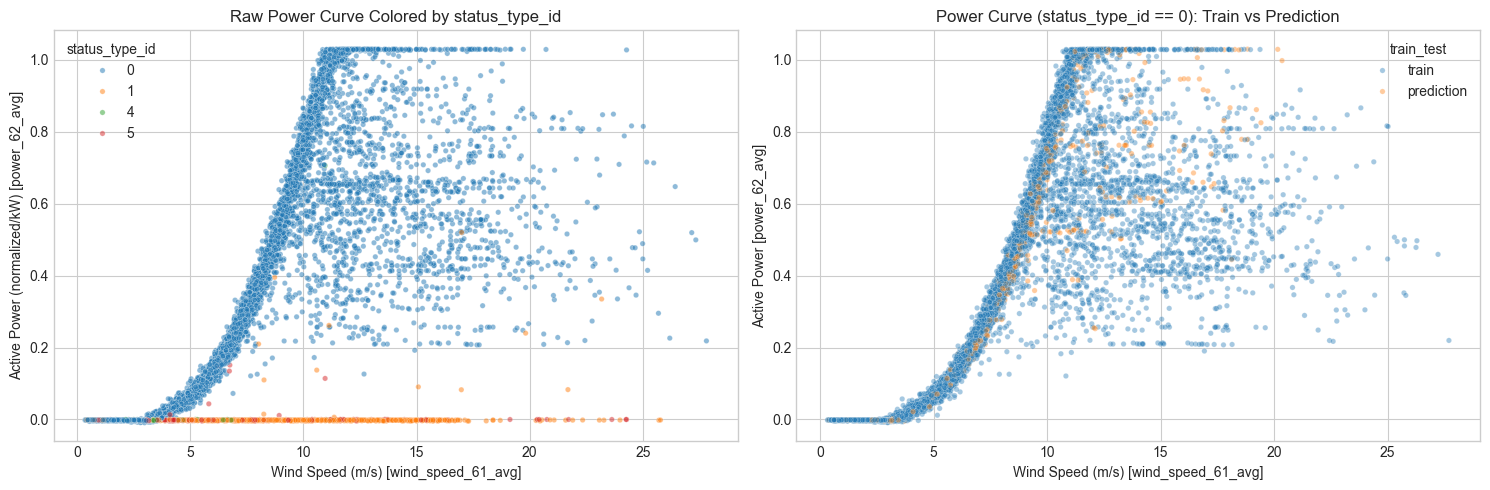

In [4]:
# Visualization 1: Wind Turbine Power Curve by Operational Status (Dataset 34)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: All operational states
sns.scatterplot(
    data=df_34.sample(8000, random_state=42),
    x="wind_speed_61_avg",
    y="power_62_avg",
    hue="status_type_id",
    palette="tab10",
    alpha=0.5,
    s=15,
    ax=axes[0]
)
axes[0].set_title("Raw Power Curve Colored by status_type_id")
axes[0].set_xlabel("Wind Speed (m/s) [wind_speed_61_avg]")
axes[0].set_ylabel("Active Power (normalized/kW) [power_62_avg]")

# Right: Train (Normal Baseline) vs Prediction Window (Normal Operation status_type_id == 0)
df_34_norm_op = df_34[df_34["status_type_id"] == 0]
sns.scatterplot(
    data=df_34_norm_op.sample(min(8000, len(df_34_norm_op)), random_state=42),
    x="wind_speed_61_avg",
    y="power_62_avg",
    hue="train_test",
    alpha=0.4,
    s=15,
    ax=axes[1]
)
axes[1].set_title("Power Curve (status_type_id == 0): Train vs Prediction")
axes[1].set_xlabel("Wind Speed (m/s) [wind_speed_61_avg]")
axes[1].set_ylabel("Active Power [power_62_avg]")

plt.tight_layout()
plt.show()

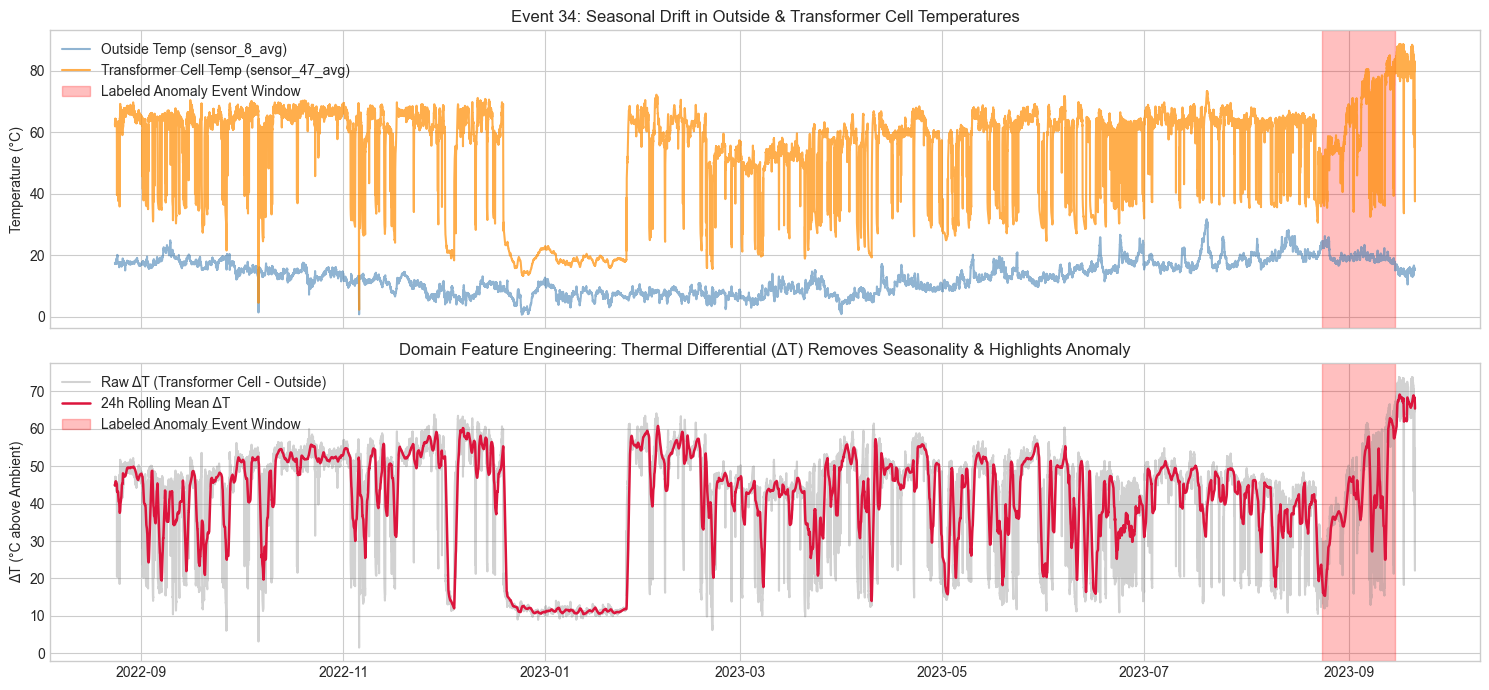

In [5]:
# Visualization 2: Raw Temperature vs Thermal Differential (Delta T) Before Failure
# In Event 34, the fault is 'high temperature in transformer cell' (sensor_47_avg)
# Outside temperature is sensor_8_avg
ev34_meta = event_info[event_info["event_id"] == 34].iloc[0]
ev_start, ev_end = ev34_meta["event_start"], ev34_meta["event_end"]

df_34["transformer_cell_delta_T"] = df_34["sensor_47_avg"] - df_34["sensor_8_avg"]
df_34["transformer_delta_T_24h_mean"] = df_34["transformer_cell_delta_T"].rolling(144, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

# Top: Raw Temperatures
axes[0].plot(df_34["time_stamp"], df_34["sensor_8_avg"], label="Outside Temp (sensor_8_avg)", alpha=0.6, color="steelblue")
axes[0].plot(df_34["time_stamp"], df_34["sensor_47_avg"], label="Transformer Cell Temp (sensor_47_avg)", alpha=0.7, color="darkorange")
axes[0].axvspan(ev_start, ev_end, color="red", alpha=0.25, label="Labeled Anomaly Event Window")
axes[0].set_title("Event 34: Seasonal Drift in Outside & Transformer Cell Temperatures")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend(loc="upper left")

# Bottom: Thermal Differential (Delta T) + 24h Rolling Mean
axes[1].plot(df_34["time_stamp"], df_34["transformer_cell_delta_T"], label="Raw ΔT (Transformer Cell - Outside)", alpha=0.35, color="gray")
axes[1].plot(df_34["time_stamp"], df_34["transformer_delta_T_24h_mean"], label="24h Rolling Mean ΔT", color="crimson", linewidth=1.8)
axes[1].axvspan(ev_start, ev_end, color="red", alpha=0.25, label="Labeled Anomaly Event Window")
axes[1].set_title("Domain Feature Engineering: Thermal Differential (ΔT) Removes Seasonality & Highlights Anomaly")
axes[1].set_ylabel("ΔT (°C above Ambient)")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

---
## Step 4: Statistical Time-Series Checks (Stationarity & Autocorrelation)

Let's run the **Augmented Dickey-Fuller (ADF)** test to prove mathematically why:
1. Cumulative counters (`sensor_0` to `sensor_3`: kWh/kvarh) are **non-stationary** ($p > 0.05$) and must either be differenced ($\Delta x_t = x_t - x_{t-1}$) or dropped in favor of instantaneous power (`power_62_avg`, `reactive_power_11_avg`).
2. Raw temperatures have strong seasonal non-stationarity, whereas **thermal differentials ($\Delta T$)** are much more stationary on normal training data.

In [6]:
from statsmodels.tsa.stattools import adfuller

# Run ADF test on hourly-subsampled training data (for speed)
train_sub = df_34[df_34["train_test"] == "train"].iloc[::6]

test_cols = {
    "Cumulative Counter (sensor_3_avg - Total Active Energy)": "sensor_3_avg",
    "Instantaneous Active Power (power_62_avg)": "power_62_avg",
    "Wind Speed (wind_speed_61_avg)": "wind_speed_61_avg",
    "Raw Outside Temp (sensor_8_avg)": "sensor_8_avg",
    "Engineered Thermal Diff (transformer_cell_delta_T)": "transformer_cell_delta_T",
}

adf_rows = []
for label, col in test_cols.items():
    series = train_sub[col].dropna()
    stat, pval, _, _, _, _ = adfuller(series, maxlag=24)
    adf_rows.append({
        "Feature": label,
        "ADF Statistic": round(stat, 3),
        "p-value": round(pval, 5),
        "Stationary (p < 0.05)?": "Yes" if pval < 0.05 else "No (Non-Stationary)"
    })

display(pd.DataFrame(adf_rows))

,Feature,ADF Statistic,p-value,Stationary (p < 0.05)?
0,Cumulative Counter (sensor_3_avg - Total Activ...,-9.675,0.00000,Yes
1,Instantaneous Active Power (power_62_avg),-10.046,0.00000,Yes
2,Wind Speed (wind_speed_61_avg),-10.813,0.00000,Yes
3,Raw Outside Temp (sensor_8_avg),-3.484,0.00842,Yes
4,Engineered Thermal Diff (transformer_cell_delt...,-7.685,0.00000,Yes


---
## Step 5: Complete WP1 Preprocessing & Feature Engineering Pipeline

Based on our EDA findings above, here is our justified preprocessing strategy for WP2 (Clustering) and WP3 (Change Point Detection):
1. **Drop Cumulative Counters (`sensor_0`..`sensor_3`):** They grow monotonically or reset arbitrarily, which corrupts distance-based clustering and change-point detection.
2. **Focus on `_avg` and `_std` statistics (or key physical channels):** Reduces collinearity between `_min`, `_max`, and `_avg` of the exact same 10-minute window.
3. **Cyclic Encoding for Angles (`sensor_4`, `sensor_10`, `sensor_21`):** Replace $0^\circ$–$360^\circ$ angles with $\sin(2\pi \theta / 360)$ and $\cos(2\pi \theta / 360)$.
4. **Thermal Differentials ($\Delta T = T_{\text{component}} - T_{\text{outside}}$):** Subtract `sensor_8_avg` (outside temperature) from internal bearing, gearbox, and transformer temperatures (`sensor_31` to `sensor_53`) to remove summer/winter seasonal drift.
5. **Multi-Horizon Rolling Features (6h = 36 steps, 24h = 144 steps):** Capture temporal trend and volatility.
6. **Leakage-Free Scaling & PCA:** Fit `RobustScaler` and `PCA(n_components=0.95)` **strictly on normal training data (`train_test == 'train'` and `status_type_id == 0`)**, then transform the full time series.

In [7]:
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

def preprocess_wind_farm_b_dataset(df: pd.DataFrame, pca_variance: float = 0.95):
    """
    Self-contained WP1 preprocessing & feature engineering function for a Wind Farm B dataset.
    Returns:
        df_feat: Engineered DataFrame
        X_scaled: Robust-scaled feature matrix
        X_pca: PCA-reduced feature matrix (fitted only on normal training rows)
        pca_model: Fitted PCA object
    """
    data = df.sort_values("time_stamp").reset_index(drop=True).copy()
    meta_cols = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]
    
    # 1. Drop cumulative counter sensors (sensor_0, sensor_1, sensor_2, sensor_3)
    counter_prefixes = ("sensor_0_", "sensor_1_", "sensor_2_", "sensor_3_")
    drop_cols = [c for c in data.columns if c.startswith(counter_prefixes)]
    data.drop(columns=drop_cols, inplace=True)
    
    # 2. Interpolate short missing gaps (up to 6 steps = 1 hour)
    num_cols = [c for c in data.columns if c not in meta_cols]
    data[num_cols] = data[num_cols].interpolate(method="linear", limit=6)
    
    # 3. Cyclic encoding for angular sensors (sensor_4, sensor_10, sensor_21)
    for angle_base in ["sensor_4", "sensor_10", "sensor_21"]:
        col = f"{angle_base}_avg"
        if col in data.columns:
            rad = np.deg2rad(data[col] % 360.0)
            data[f"{col}_sin"] = np.sin(rad)
            data[f"{col}_cos"] = np.cos(rad)
            # Drop raw angle avg/min/max to avoid 0/360 jump discontinuities
            raw_angle_cols = [c for c in data.columns if c.startswith(f"{angle_base}_") and not c.endswith(("_sin", "_cos", "_std"))]
            data.drop(columns=raw_angle_cols, inplace=True)
            
    # 4. Thermal differentials (Component Temp - Outside Temp sensor_8_avg)
    internal_temp_ids = list(range(31, 54))  # sensor_31 through sensor_53 are all internal °C sensors
    delta_t_cols = {}
    if "sensor_8_avg" in data.columns:
        outside_t = data["sensor_8_avg"]
        for tid in internal_temp_ids:
            tcol = f"sensor_{tid}_avg"
            if tcol in data.columns:
                delta_t_cols[f"sensor_{tid}_delta_T"] = data[tcol] - outside_t
    if delta_t_cols:
        data = pd.concat([data, pd.DataFrame(delta_t_cols, index=data.index)], axis=1)
        
    # 5. Rolling 24-hour (144 steps) mean on key health indicators (Delta T, Vibration, Power)
    key_roll_cols = [c for c in delta_t_cols.keys()] + ["sensor_54_avg", "sensor_55_avg", "sensor_56_avg", "power_62_avg"]
    key_roll_cols = [c for c in key_roll_cols if c in data.columns]
    rolled_24h = data[key_roll_cols].rolling(window=144, min_periods=1).mean().add_suffix("_roll24h")
    data = pd.concat([data, rolled_24h], axis=1)
    
    # 6. Leakage-free RobustScaler + PCA fitted strictly on Normal Training Data
    feature_cols = [c for c in data.columns if c not in meta_cols]
    train_normal_mask = (data["train_test"] == "train") & (data["status_type_id"] == 0)
    
    train_medians = data.loc[train_normal_mask, feature_cols].median()
    X_all = data[feature_cols].fillna(train_medians).fillna(0.0)
    
    scaler = RobustScaler()
    scaler.fit(X_all.loc[train_normal_mask])
    X_scaled = np.clip(scaler.transform(X_all), -15.0, 15.0)  # clip extreme sensor glitches
    
    pca = PCA(n_components=pca_variance, random_state=42)
    pca.fit(X_scaled[train_normal_mask.values])
    X_pca = pca.transform(X_scaled)
    
    return data, X_scaled, X_pca, pca

# Test on Dataset 34
df_34_feat, X_34_scaled, X_34_pca, pca_34 = preprocess_wind_farm_b_dataset(df_34)
print(f"Engineered feature count: {X_34_scaled.shape[1]} -> Reduced to {X_34_pca.shape[1]} PCA components (95% variance)")

Engineered feature count: 285 -> Reduced to 25 PCA components (95% variance)
